In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P']

In [2]:
# closure test? i.e. there is truth pythia data somewhere to compare to
closure = True

JETPT_BINS = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500], dtype=np.float64)

RL_NBINS = 25
RL_MIN, RL_MAX = 0.01, 1.0
RL_BINS = np.logspace(np.log10(RL_MIN), np.log10(RL_MAX), RL_NBINS + 1)

W_NBINS = 20 #30 #100
W_MIN, W_MAX = 0.0, 0.3 #1.0 #0.3
W_BINS = np.logspace(-5,-0.5,W_NBINS+1)


# define binnings
n_bins_true = [9, 25, 20] # jet pt, RL, weight #[20, 12, 6] # [20, 22, 7] # WARNING RooUnfold seg faults if too many bins used
RL_bins = RL_BINS
# binning = [np.logspace(-5,0,n_bins_true[0]+1), \
#             np.logspace(-2.299,0,n_bins_true[1]+1), \
#             np.array([5, 10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning = [JETPT_BINS, \
           RL_bins, \
           W_BINS ]
print(binning)
bincenters = [ get_log_bincenters(binning[0]), get_log_bincenters(binning[1]), get_lin_bincenters(binning[2]) ]
binwidths = [ get_binwidths(a) for a in binning ]

n_bins = [9, 25, 20] #n_bins = [20, 22, 6]
# binning_reco = [np.logspace(-5,0,n_bins[0]+1), \
#             np.logspace(-2.299,0,n_bins[1]+1), \
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning_reco = [JETPT_BINS, \
                RL_bins, \
                W_BINS ]
bincenters_reco = [ get_log_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_lin_bincenters(binning_reco[2]) ]
binwidths_reco = [ np.array(get_binwidths(a)) for a in binning_reco ]

labels = ["energy weight", "$R_L$", "jet $p_T$"]

n_iter = 3

[array([ 10.,  20.,  40.,  60.,  80., 100., 120., 150., 200., 500.]), array([0.01      , 0.01202264, 0.0144544 , 0.01737801, 0.02089296,
       0.02511886, 0.03019952, 0.03630781, 0.04365158, 0.05248075,
       0.06309573, 0.07585776, 0.09120108, 0.10964782, 0.13182567,
       0.15848932, 0.19054607, 0.22908677, 0.27542287, 0.33113112,
       0.39810717, 0.47863009, 0.57543994, 0.69183097, 0.83176377,
       1.        ]), array([1.00000000e-05, 1.67880402e-05, 2.81838293e-05, 4.73151259e-05,
       7.94328235e-05, 1.33352143e-04, 2.23872114e-04, 3.75837404e-04,
       6.30957344e-04, 1.05925373e-03, 1.77827941e-03, 2.98538262e-03,
       5.01187234e-03, 8.41395142e-03, 1.41253754e-02, 2.37137371e-02,
       3.98107171e-02, 6.68343918e-02, 1.12201845e-01, 1.88364909e-01,
       3.16227766e-01])]


In [3]:
# file defs, hist imports

# f_unfolded = ur.open("./unfolded_closure.root")
# f_unfolded1D = ur.open("./unfolded_1D_closure.root")
# f_preunfold_rm = ur.open("./preunfold_rm.root")
# f_preunfold_data = ur.open("./preunfold_fullsimdata.root")

f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded.root")
f_unfolded1D = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/response_groomed_forunfolding_merged.root")
f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/58416144/AnalysisResultsMerged_groomedbins.root")
    


In [ ]:
def get_histograms(lab, f_preunfold_data, f_preunfold_rm, f_unfolded)
    # Data, reco [theta_unknown_S]
    h3_raw = f_preunfold_data["{}_sd0.1_raw".format(lab)] #f_preunfold_data["raw"]
    h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"] #f_preunfold_data["raw1D"]

    # MC, reco [theta0_S]
    h3_reco = f_preunfold_rm["groomed_{}_reco".format(lab)] #f_preunfold_rm["reco"]
    h1_true = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #f_preunfold_rm["reco1D"]

    # MC, true [theta0_G]
    h3_gen = f_preunfold_rm["groomed_{}_gen".format(lab)] #f_preunfold_rm["gen"]
    h1_gen = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #f_preunfold_rm["gen1D"]

    # Data, true [theta_unknown_G]
    if closure:
        h3_true = f_preunfold_data["true"] #TODO
        h1_true = f_preunfold_data["true1D"] #TODO

    h3_unfolded = []
    #h1_unfolded = [] TODO add in h1 unfolded support
    for i in range(1,n_iter+1):
        h3_unfolded.append(f_unfolded["Bayesian_Unfolded_{}_iter{}".format(lab, i)]) #f_unfolded["Bayesian_Unfoldediter{}".format(i)])

    # EEC distributions, binned in (RL, jet pT)
    h2_raw_eec = f_preunfold_data["raw_eec"] #TODO
    h2_true_eec = f_preunfold_data["true_eec"] #TODO

    return h3_raw, h1_raw, h3_reco, h1_true, h3_gen, h1_gen, h3_true, h1_true, h3_unfolded, h2_raw_eec, h2_true_eec
h3_raw, h1_raw, h3_reco, h1_true, h3_gen, h1_gen, h3_true, h1_true, h3_unfolded, h2_raw_eec, h2_true_eec = get_histograms(lab, f_preunfold_data, f_preunfold_rm, f_unfolded)


In [4]:
# ref: https://hepunx.rl.ac.uk/~adye/software/unfold/htmldoc-dev/src/RooUnfoldResponse.cxx.html#FHDYLE
def FindBin(binx, biny, binz):
    assert binx < n_bins[0] and biny < n_bins [1] and binz < n_bins[2] \
            and 0 <= binx and 0 <= biny and 0 <= binz
    return binx + n_bins[0]*(biny + n_bins[1]*binz)

def FindIndex(bin_n):
    binz = bin_n // (n_bins_true[0] * n_bins_true[1])
    bin_n -= binz * (n_bins_true[0] * n_bins_true[1])

    biny = bin_n // n_bins_true[0]
    binx = bin_n % n_bins_true[0]

    return binx, biny, binz
    

matrix = f_unfolded["matrix"].values()
matrix1D = f_unfolded1D["matrix1D"].values()

[matrixx, matrixy, matrixz] = [np.zeros((n_bins[i], n_bins_true[i])) for i in range(3)]

N = n_bins_true[0]*n_bins_true[1]*n_bins_true[2]

for i in range(n_bins[0]):
    for j in range(n_bins[1]):
        for k in range(n_bins[2]):

            reco_bin = FindBin(i, j, k)
            for m in range(N):
                
                binx, biny, binz = FindIndex(m)
                bincontent = matrix[reco_bin][m]

                matrixx[i][binx] += bincontent
                matrixy[j][biny] += bincontent
                matrixz[k][binz] += bincontent

matricies = [matrixx, matrixy, matrixz]


/tmp/ipykernel_1785356/2761922307.py:12: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


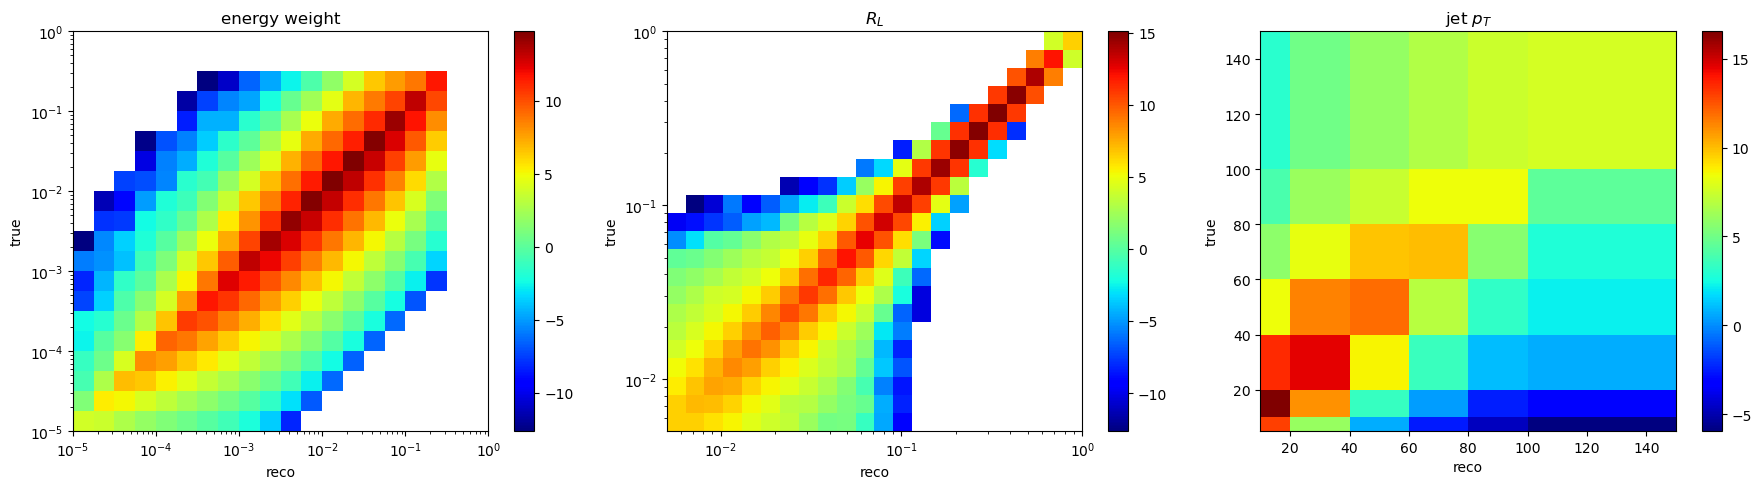

In [5]:
# print response matricies

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i in range(3):
    ax = axes[i]

    # Plot histograms
    #ax.imshow(matrix.values(), origin='lower', extent=[binning[0][0], binning[0][-1], binning[0][0], binning[0][-1]], cmap='viridis')
    h = matricies[i]
    plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')
    ax.set_title(labels[i])
    ax.set_xlabel('reco')
    ax.set_ylabel('true')

    if i in [0,1]:
        ax.set_xscale('log')
        ax.set_yscale('log')

    fig.colorbar(plot)


# Show plot
plt.tight_layout()
plt.show()

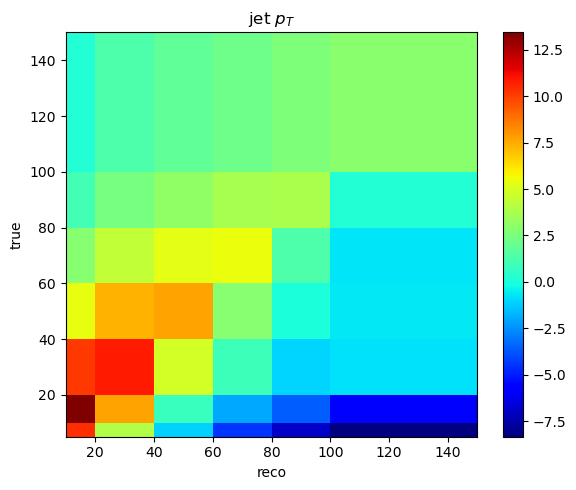

In [6]:
# print 1D response matrix

# Create subplots
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

# Plot histograms
h = matrix1D
plot = ax.pcolormesh(binning_reco[2], binning[2], np.log(h, out=np.zeros_like(h), where=(h!=0)).T, cmap='jet')
ax.set_title(labels[2])
ax.set_xlabel('reco')
ax.set_ylabel('true')

fig.colorbar(plot)

# Show plot
plt.tight_layout()
plt.show()

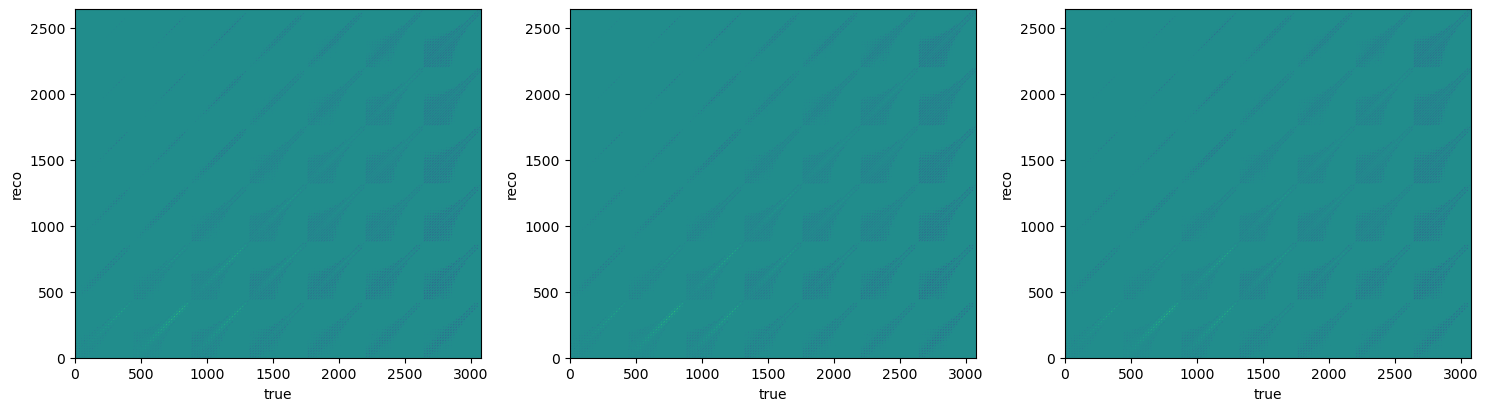

In [7]:
# print response matricies

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    ax = axes[i]

    # Plot histograms
    #ax.imshow(matrix.values(), origin='lower', extent=[binning[0][0], binning[0][-1], binning[0][0], binning[0][-1]], cmap='viridis')
    ax.imshow(np.log(matrix, out=np.zeros_like(matrix), where=(matrix!=0)), origin='lower', cmap='viridis')
    ax.set_xlabel('true')
    ax.set_ylabel('reco')
    #ax.set_xscale('log')
    #ax.set_yscale('log')


# Show plot
plt.tight_layout()
plt.show()

In [8]:
proj = lambda a : [projectionX(a.values()), projectionY(a.values()), projectionZ(a.values())]
proj_err = lambda a : [projectionX(a.errors()), projectionY(a.errors()), projectionZ(a.errors())]
proj_purity = lambda a: proj(a)
#proj_purity = lambda a : np.array([projectionX(a.values()*h3_purity.values()), projectionY(a.values()*h3_purity.values()), projectionZ(a.values()*h3_purity.values())])

theta0_G = proj(h3_gen)
theta0_S = proj(h3_reco)
theta_unknown_G = proj_purity(h3_true)
theta_unknown_S = proj(h3_raw)

theta_unfolded = [proj(a) for a in h3_unfolded]

theta0_G_err = proj_err(h3_gen)
theta0_S_err = proj_err(h3_reco)
theta_unknown_G_err = proj_err(h3_true)
theta_unknown_S_err = proj_err(h3_raw)

theta_unfolded_err = [proj_err(a) for a in h3_unfolded]

matrixify = lambda A : projectionXY(A.values()).T
matrixify_err = lambda A: projectionXY(A.errors()).T
#matrixify_purity = lambda A : projectionXY(A.values() * h3_purity.values()).T

#U_true = matrixify_purity(h3_true)
U_true = matrixify(h3_true)

U_unfolded = [matrixify(A) for A in h3_unfolded]
U_unfolded_err = [matrixify_err(A) for A in h3_unfolded]

print(theta0_G)



[array([3.26959808e+02, 1.32804824e+03, 4.86480579e+03, 1.65217524e+04,
       5.33007661e+04, 1.63939902e+05, 4.78293319e+05, 1.30983807e+06,
       3.18240249e+06, 6.53242165e+06, 1.15134755e+07, 1.76544790e+07,
       2.32288979e+07, 2.58978162e+07, 2.40394249e+07, 1.77888002e+07,
       9.58930971e+06, 2.89140156e+06, 0.00000000e+00, 0.00000000e+00]), array([1.95545735e+04, 3.12566899e+04, 4.69542101e+04, 7.18574371e+04,
       1.16612839e+05, 1.84845223e+05, 2.95699583e+05, 4.77122120e+05,
       7.69731757e+05, 1.24419891e+06, 2.00728977e+06, 3.20476935e+06,
       5.10407518e+06, 8.04143714e+06, 1.23889438e+07, 1.85075753e+07,
       2.59537109e+07, 3.09769561e+07, 2.34417451e+07, 9.88685796e+06,
       1.56577295e+06, 9.87592160e+03]), array([1.10558437e+08, 2.89509041e+07, 4.36351120e+06, 3.77793369e+05,
       6.89689899e+04, 1.81530199e+04, 9.07529947e+03])]


In [9]:
for iteration in range(n_iter):
    print(theta_unfolded[iteration][1])

[2.38779412e+04 3.81078508e+04 5.00719285e+04 7.50500097e+04
 1.18848663e+05 1.86105230e+05 2.96399618e+05 4.77467116e+05
 7.69863307e+05 1.24426701e+06 2.00734112e+06 3.20482457e+06
 5.10414360e+06 8.04152109e+06 1.23890455e+07 1.85076963e+07
 2.59538508e+07 3.09771020e+07 2.34418359e+07 9.88689318e+06
 1.56578138e+06 9.78328437e+03]
[2.65334291e+04 4.23571163e+04 5.02799139e+04 7.49709100e+04
 1.18045427e+05 1.85152681e+05 2.95387833e+05 4.76828384e+05
 7.69518775e+05 1.24409753e+06 2.00727985e+06 3.20480671e+06
 5.10413986e+06 8.04151851e+06 1.23890416e+07 1.85076905e+07
 2.59538434e+07 3.09770940e+07 2.34418306e+07 9.88689085e+06
 1.56578091e+06 9.78328767e+03]
[2.87150508e+04 4.58092691e+04 4.99532169e+04 7.44410462e+04
 1.17199919e+05 1.84445677e+05 2.94768773e+05 4.76665037e+05
 7.69523152e+05 1.24416280e+06 2.00733011e+06 3.20483723e+06
 5.10415182e+06 8.04152425e+06 1.23890480e+07 1.85076984e+07
 2.59538531e+07 3.09771038e+07 2.34418366e+07 9.88689290e+06
 1.56578124e+06 9.783

[6.54045654e+01 2.98817557e+02 1.19765411e+03 4.43614138e+03
 1.53410810e+04 4.93700896e+04 1.41958303e+05 3.41624849e+05
 7.08477093e+05 1.28417601e+06 2.03288117e+06 2.79060317e+06
 3.28447368e+06 3.27740895e+06 2.67358861e+06 1.64159115e+06
 6.86248399e+05 1.35354757e+05 0.00000000e+00 0.00000000e+00]
[2.77831871e+03 4.14373678e+03 6.86217444e+03 1.13964695e+04
 1.80844755e+04 2.97739226e+04 4.76886746e+04 7.88332398e+04
 1.29233594e+05 2.08245884e+05 3.32025352e+05 5.24006531e+05
 8.15791439e+05 1.24053057e+06 1.82367512e+06 2.56667842e+06
 3.36475949e+06 3.75075309e+06 2.76872249e+06 1.16486238e+06
 1.79531847e+05 7.18112283e+02]
[1.65555934e+07 2.29691038e+06 1.78047326e+05 2.89642514e+04
 6.76798383e+03 2.81199825e+03]


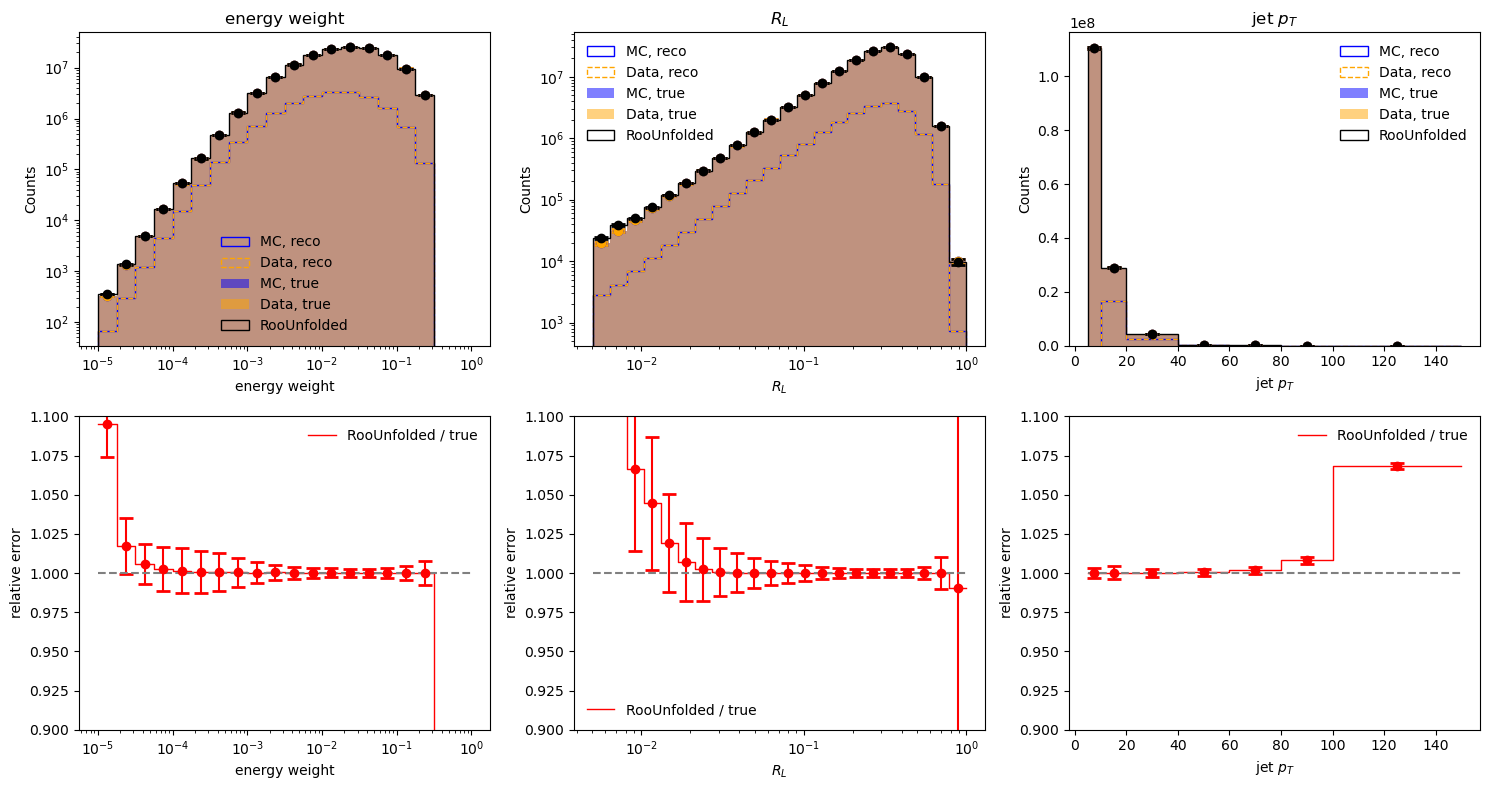

In [10]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

for iteration in range(1):
    fig, axes = plt.subplots(2, 3, figsize=(15,8))

    # ROW 1: raw distributions
    for i in range(3):
        ax = axes[0, i]

        _,_,_=ax.hist(binning_reco[i][:-1], binning_reco[i], weights=theta0_S[i],color='blue', histtype="step", alpha=1, label="MC, reco")
        print(theta0_S[i])
        _,_,_=ax.hist(binning_reco[i][:-1], binning_reco[i], weights=theta_unknown_S[i],color='orange',histtype="step",linestyle='--',alpha=1,label="Data, reco")

        _,_,_=ax.hist(binning[i][:-1], binning[i], weights=theta0_G[i],color='blue', alpha=0.5, label="MC, true")
        _,_,_=ax.hist(binning[i][:-1], binning[i], weights=theta_unknown_G[i],color='orange',alpha=0.5,label="Data, true")
        _,_,_=ax.hist(binning[i][:-1], binning[i],weights=theta_unfolded[iteration][i],color='black',histtype="step",label="RooUnfolded",lw=1)

        ax.errorbar(bincenters[i], theta0_G[i], yerr=theta0_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='blue')
        ax.errorbar(bincenters[i], theta_unknown_G[i], yerr=theta_unknown_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='orange')
        ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color='black')
        
        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("Counts")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
            ax.set_yscale('log')
            #ax.set_ylim([0.1, 4E8])
    
    # ROW 2: residual plots
    for i in range(3):
        ax = axes[1, i]
        
        yvals, yerrs = get_ratio_safe(theta_unfolded[iteration][i], theta_unknown_G[i], \
                                      numerr=theta_unfolded_err[iteration][i], denomerr=theta_unknown_G_err[i])
        
        ax.step(binning[i], np.insert(yvals, 0, yvals[0]), where="pre",color='red',label="RooUnfolded / true",lw=1)
        ax.errorbar(bincenters[i], yvals, yerr=yerrs, capsize=5, capthick=2, fmt='o', linestyle="None", color='red')

        ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_xlabel(labels[i])
        ax.set_ylabel("relative error")
        ax.legend(frameon=False)
        
        if i in [0, 1]:
            ax.set_xscale('log')
            ax.set_ylim([0.9, 1.1])
        else:
            ax.set_ylim([0.9, 1.1])

    
    fig.tight_layout()
    # fig.savefig("post_training_" + str(iteration) + ".png")
    # fig.show()
    # plt.close()
plt.show()

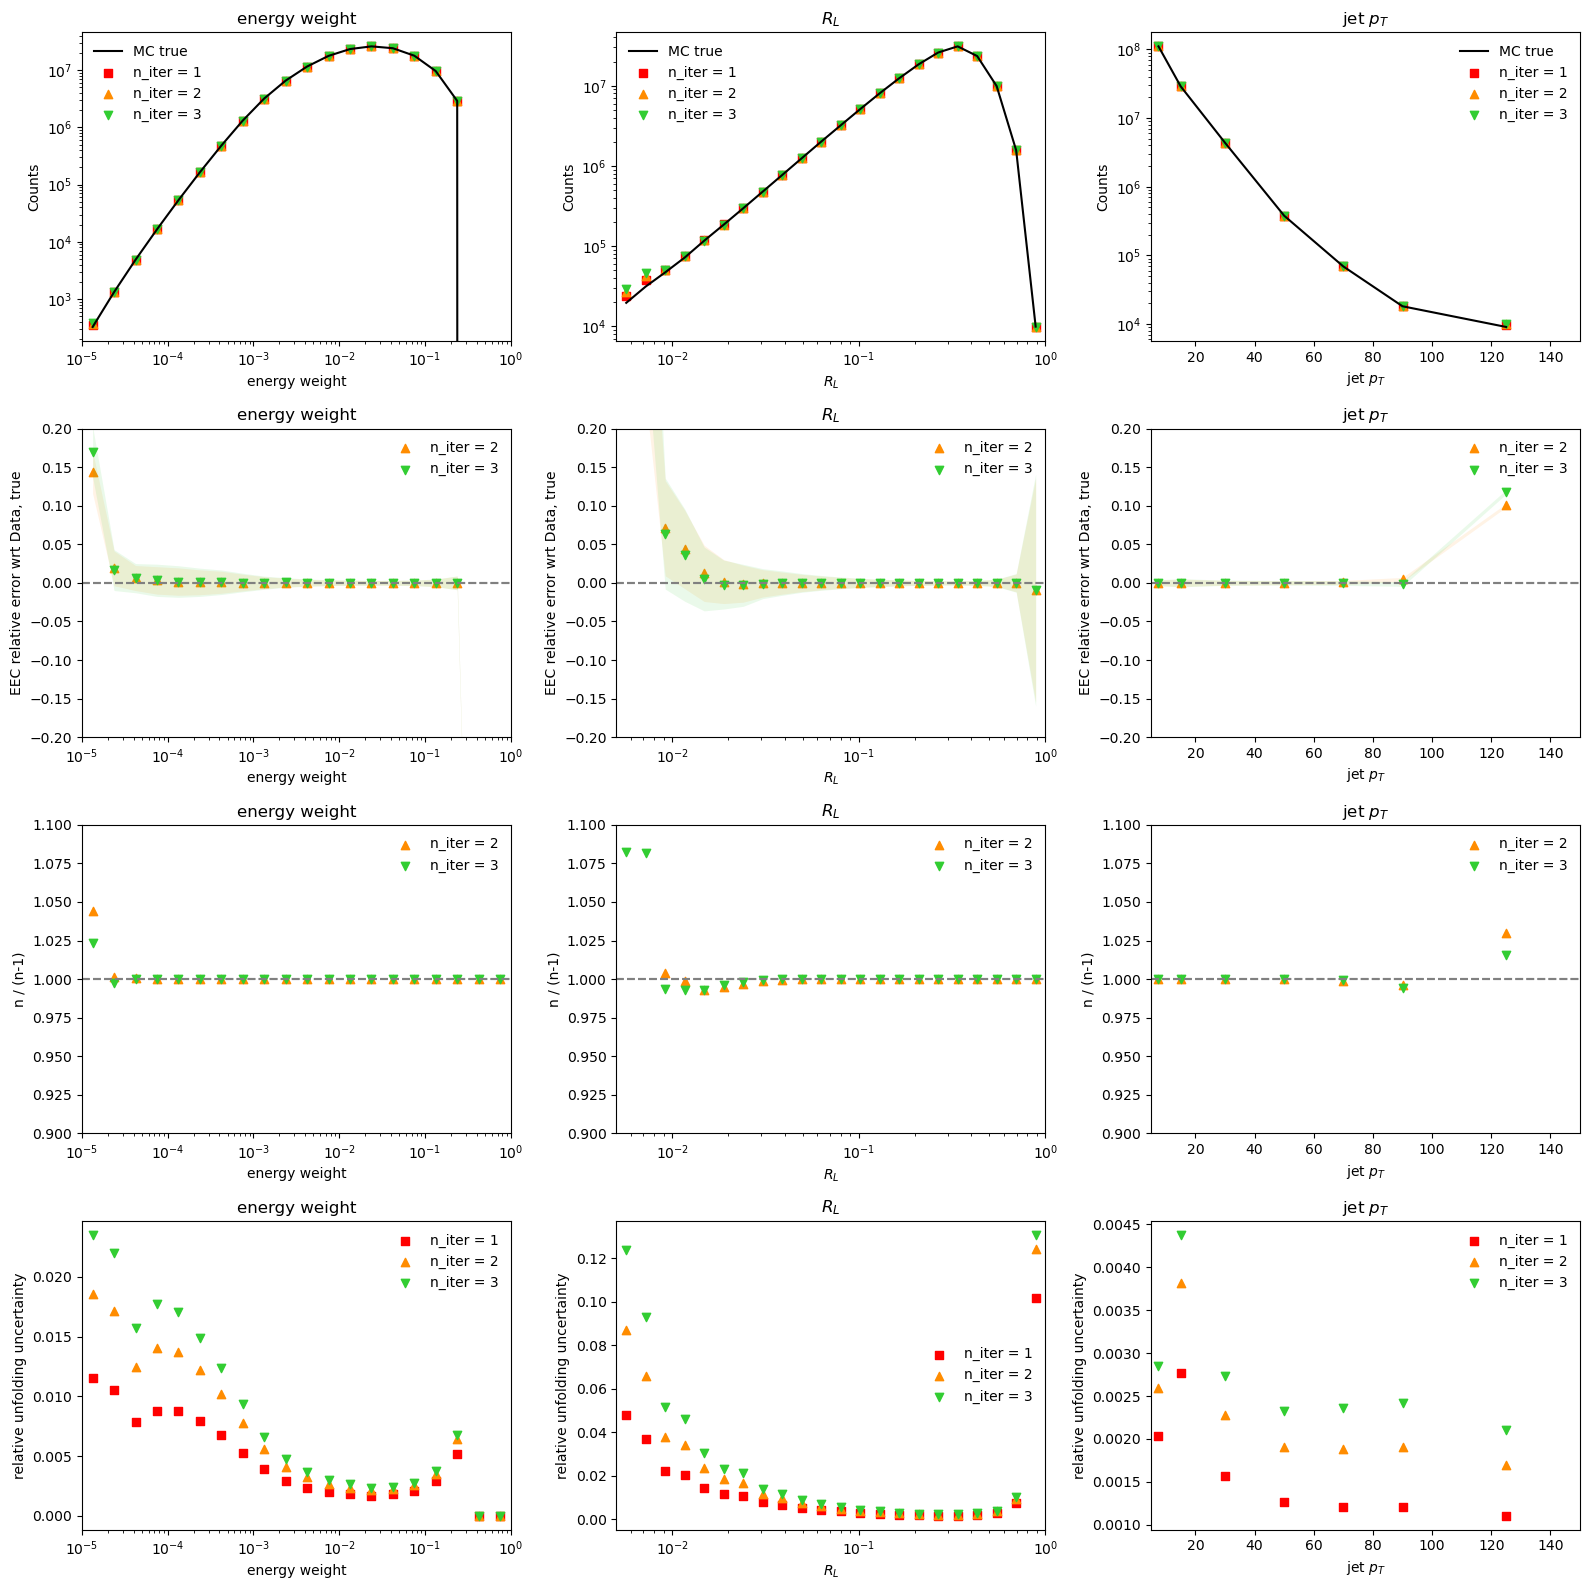

In [11]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

it = 3

fig, axes = plt.subplots(4, 3, figsize=(16,16))

# ROW 1: raw distributions
for i in range(3):
    ax = axes[0, i]

    if i == 0:
        ax.plot(bincenters[i][:-1], theta_unknown_G[i][:-1], color='black',label="MC true")
    else:
        ax.plot(bincenters[i], theta_unknown_G[i], color='black',label="MC true")

    for iteration in range(it):
        ax.scatter(bincenters[i], theta_unfolded[iteration][i],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("Counts")

        #ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[iteration])
        
        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_yscale('log')
            #ax.set_ylim([0.1, 4E8])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])

# ROW 2: error wrt Data, true
for i in range(3):
    ax = axes[1, i]

    for iteration in range(1,it):

        yvals, yerrs = get_ratio_safe(theta_unfolded[iteration][i], theta_unknown_G[i], \
                                      numerr=theta_unfolded_err[iteration][i], denomerr=theta_unknown_G_err[i])
        yvals = yvals - 1

        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        if i == 0:
            ax.fill_between(bincenters[i][:-1], (yvals-yerrs)[:-1], (yvals+yerrs)[:-1], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        else:
            ax.fill_between(bincenters[i], yvals-yerrs, yvals+yerrs, alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

        ax.hlines(y=0, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("EEC relative error wrt Data, true")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_ylim([-0.2, 0.2])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


# ROW 3: convergence plot (n / n - 1)
for i in range(3):
    ax = axes[2, i]

    for iteration in range(1,it):
    
        yvals = safe_divide(theta_unfolded[iteration][i] , theta_unfolded[iteration-1][i], filler=1)
        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_ylim([0.9, 1.1])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


# ROW 4: statistical error %
for i in range(3):
    ax = axes[3, i]

    for iteration in range(it):
        
        yvals = safe_divide(theta_unfolded_err[iteration][i], theta_unfolded[iteration][i])
        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


fig.tight_layout()
plt.show()

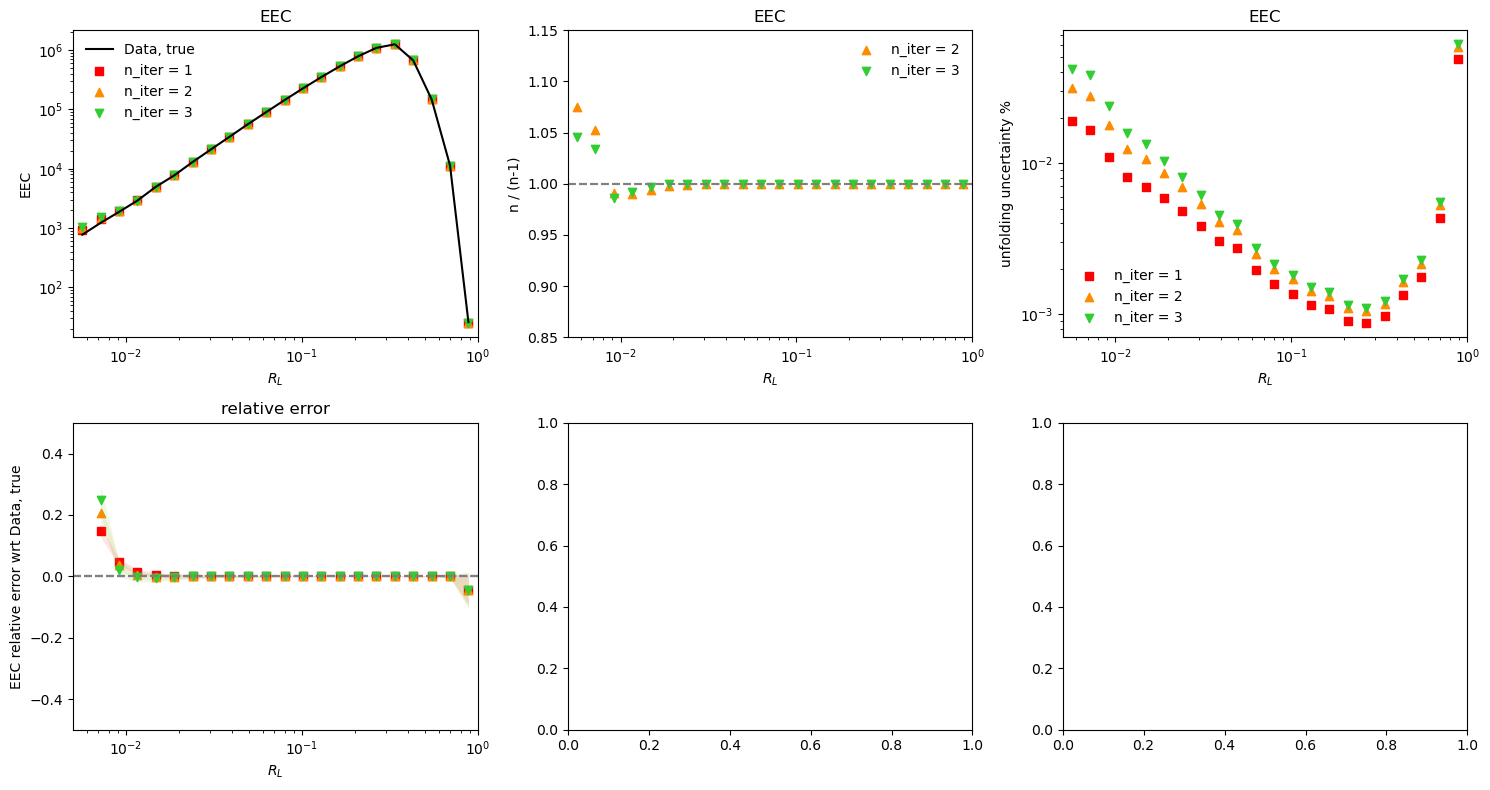

In [12]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros

it = 3

fig, axes = plt.subplots(2, 3, figsize=(15,8))

# EEC weight calculation:
# w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true])
#true_EEC_err = np.array([np.dot(col, bincenters[0]) for col in U_true_err])

unfolded_EEC = np.array([[np.dot(col, bincenters[0]) for col in U_unfolded[iteration]] for iteration in range(len(theta_unfolded))])
unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))])

# COL 1: raw EEC distribution WITH relative error over data, true underneath
ax = axes[0, 0]

rl_lims = ax.set_xlim([binning[1][0], binning[1][len(binning[1])-1]])

ax.plot(bincenters[1], true_EEC, color='black',label="Data, true")

for iteration in range(it):

    ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
    ax.set_ylabel("EEC")
    
    ax.set_title("EEC")
    ax.set_xlabel(labels[1])

    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(rl_lims)

# row below with the error

ax = axes[1, 0]

ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

for iteration in range(it):

    yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                      numerr=unfolded_EEC_err[iteration], denomerr=np.zeros_like(unfolded_EEC[iteration]), filler=1)
    yvals = yvals - 1

    ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')
    

    ax.set_title("relative error")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("EEC relative error wrt Data, true")

    ax.set_xscale('log')
    ax.set_ylim([-0.5, 0.5])
    ax.set_xlim(rl_lims)


# COL 2: convergence plot (n / n - 1)
ax = axes[0, 1]

for iteration in range(1,it):

    yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
    ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

    ax.set_title("EEC")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("n / (n-1)")
    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_ylim([0.85, 1.15])
    ax.set_xlim(rl_lims)


# COL 3: statistical error %
ax = axes[0, 2]

for iteration in range(it):
    
    yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
    ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.set_title("EEC")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("unfolding uncertainty %")
    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(rl_lims)


fig.tight_layout()
plt.show()


In [13]:
################# WENQINGS MC RECO/TRUE RATIOS #################

f_compare = ur.open("./pythiaMC_corr_hists.root")

pythia_names = ["Ratio_hJetE2C_norm_ch_jetR4_2040_trk10", "Ratio_hJetE2C_norm_ch_jetR4_4060_trk10", "Ratio_hJetE2C_norm_ch_jetR4_6080_trk10"]
h1_EEC_ratios = [f_compare[name].values() for name in pythia_names]

print(h1_EEC_ratios)

R_bins_compare = f_compare["Ratio_hJetE2C_norm_ch_jetR4_2040_trk10"].axis("x").edges()
R_bincenters_compare = get_log_bincenters(R_bins_compare)


[array([0.4063158 , 0.05553521, 0.18681993, 0.47728512, 0.15453568,
       0.1562055 , 0.26820591, 0.3964288 , 0.50627662, 0.82126412,
       0.65665351, 1.00218501, 1.04514612, 0.82443342, 0.84341768,
       0.97853643, 1.24808929, 0.76777028, 0.92868295, 0.96034384,
       0.90584581, 0.89229757, 0.82484476, 0.8048271 , 0.81635634,
       0.91060594, 0.89462787, 0.92631949, 0.94631735, 0.97929383,
       0.98813274, 1.01901363, 1.0416407 , 1.05079714, 1.05137367,
       1.05155461, 1.03547047, 1.0209294 , 1.00756739, 0.99068306,
       0.97712984, 0.96283907, 0.94322491, 0.93466936, 0.9271119 ,
       0.89425414, 0.85797969, 0.83485037, 0.78307438, 0.40896671]), array([0.09616498, 0.10855495, 0.0533472 , 0.1293675 , 0.13752767,
       0.21181488, 0.45648762, 0.58248557, 0.23455924, 0.66383562,
       0.73755381, 0.62392907, 0.73829109, 0.57108607, 0.60254996,
       0.66937369, 0.55091263, 0.63858066, 0.56714055, 0.56152391,
       0.52063601, 0.52433641, 0.52188811, 0.59607415, 0.69

In [14]:
N_jets_unf = [7.91905502e+04, 4.07895819e+03, 5.64378641e+02]
N_jets_unf_err = [3.07052137e+02, 6.42184893e+01, 2.37848329e+01]
N_jets_true = [7.92135529e+04, 4.07969140e+03, 5.64283433e+02]
N_jets_raw = [5.46348066e+04, 2.53230942e+03, 3.17720949e+02]

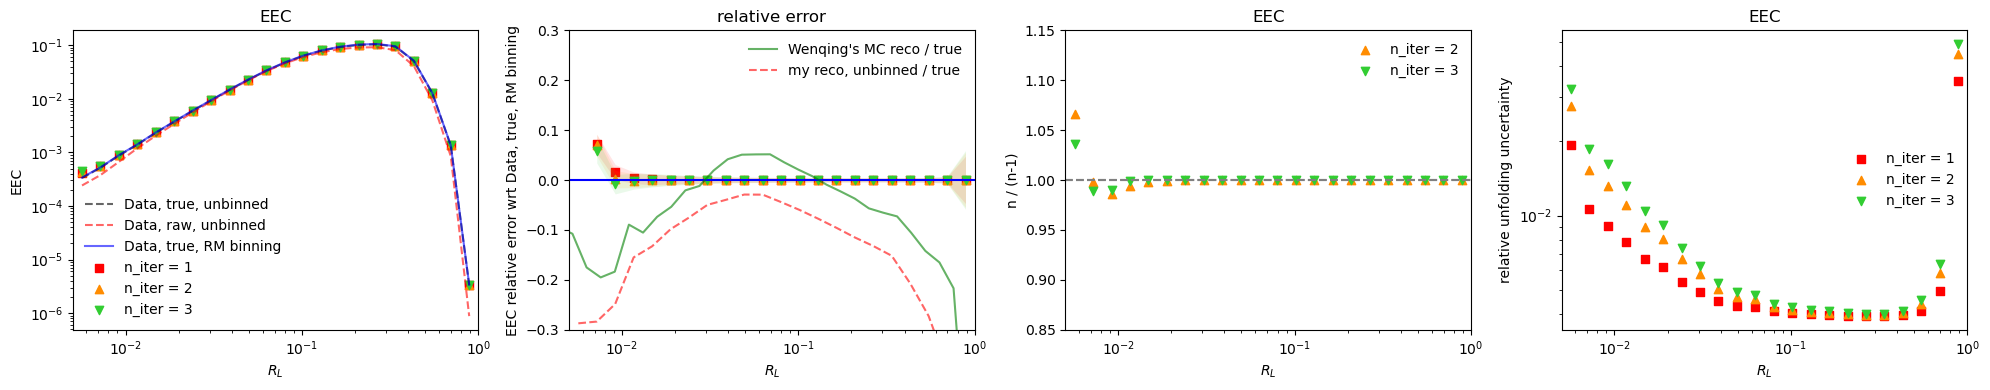

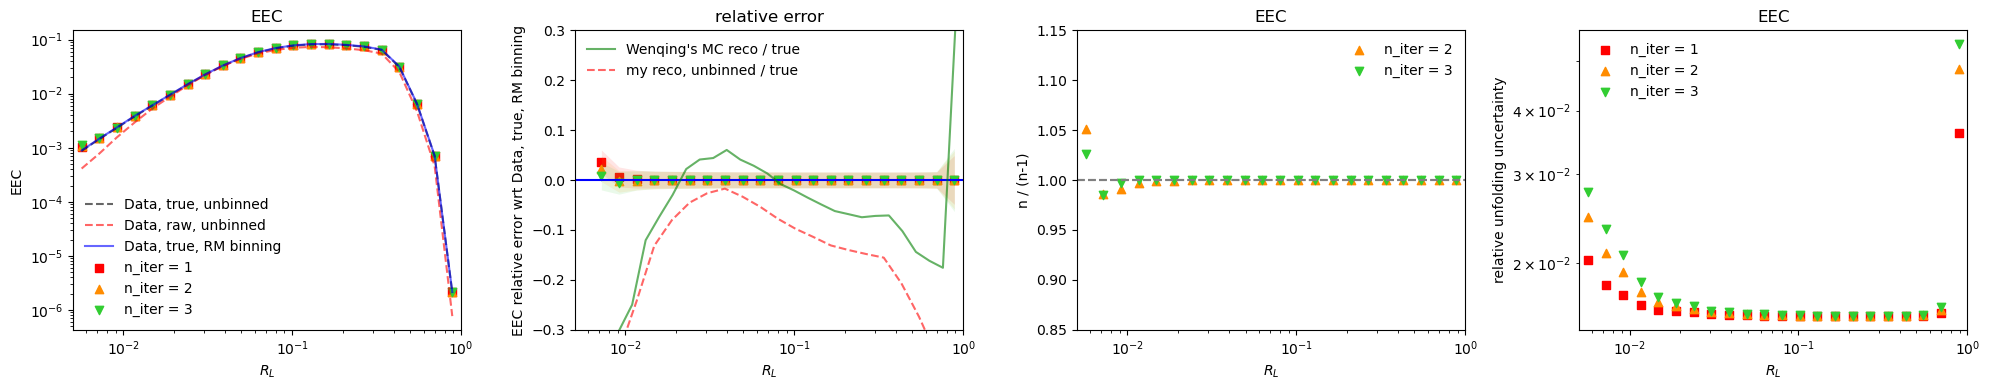

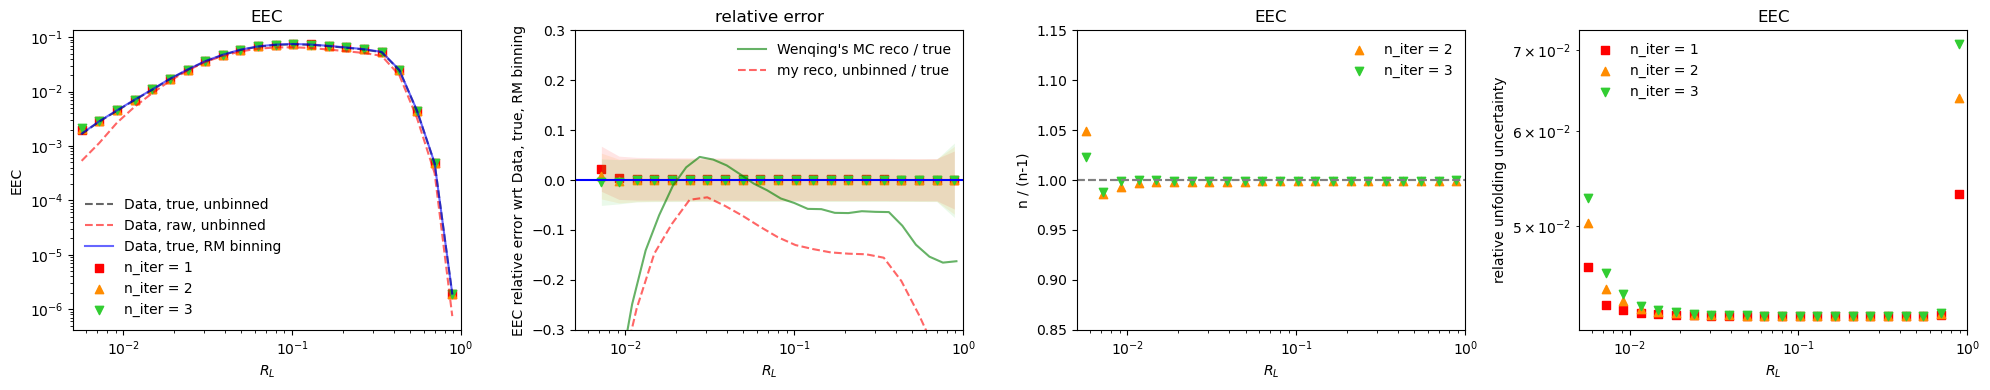

In [15]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################

# EEC distros

it = 3

j = 0
for i in range(2, 5):

    fig, axes = plt.subplots(1, 4, figsize=(20,4))

    ptcut_bins = [i, i+1]
    slice_on_pt = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    ptcut_bins_reco = [i-1, i]
    slice_on_pt_reco = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    U_true_cut = slice_on_pt(h3_true.values()) #  * h3_purity.values())
    U_true_err_cut = slice_on_pt(h3_true.errors())

    U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
    U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true_cut]) / N_jets_true[j]
    true_EEC_err = np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_true_err_cut]) / N_jets_true[j]

    unfolded_EEC = np.array([[np.dot(col, bincenters[0]) for col in U_unfolded_cut[iteration]] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err_cut[iteration]] for iteration in range(len(theta_unfolded))])

    # divide by number of jets, and propagate error in number of unfolded jets
    unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[j], unfolded_EEC_err[iteration], N_jets_unf_err[j]) for iteration in range(len(theta_unfolded))])
    unfolded_EEC /= N_jets_unf[j]

    #unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))]) / N_jets_unf[j]

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[0]

    rl_lims = ax.set_xlim([binning[1][0], binning[1][len(binning[1])-1]])

    # various comparison EEC plots

    # Data, true, unbinned in energy weight (is the actaul truth)
    # should be close to RM binning when energy weight granulatrity is ok, also used to check definition of energy weight log bin center
    # apply purity correction too
    true_eec_unbinned = yslice(h2_true_eec.values(), ptcut_bins[0], ptcut_bins[1]) / N_jets_true[j]
    true_eec_unbinned_err = yslice(h2_true_eec.errors(), ptcut_bins[0], ptcut_bins[1]) / N_jets_true[j]
    ax.plot(bincenters[1], true_eec_unbinned, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    # Data, raw, unbinned in energy weight
    raw_eec_unbinned = yslice(h2_raw_eec.values(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / N_jets_raw[j]
    raw_eec_unbinned_err = yslice(h2_raw_eec.errors(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / N_jets_raw[j]
    ax.plot(bincenters[1], raw_eec_unbinned, color='red', alpha=0.6, linestyle='dashed', label="Data, raw, unbinned")

    # Data, true, RM binning with binnings from the response matrix (i.e. calculated with some binned energy weight)
    ax.plot(bincenters[1], true_EEC, color='blue', alpha=0.6, label="Data, true, RM binning")

    #print(true_eec_unbinned / raw_eec_unbinned)

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("EEC")
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    # row below with the error

    ax = axes[1]

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='blue', linestyle='solid')

    # compare with Wenqing's reco / true ratios
    ax.plot(R_bincenters_compare, h1_EEC_ratios[j] - 1, color='green', alpha=0.6, label="Wenqing's MC reco / true")

    yvals, yerrs = get_ratio_safe(true_eec_unbinned, true_EEC, \
                                        numerr=true_EEC_err, denomerr=true_eec_unbinned_err, filler=1)
    yvals = yvals - 1
    #ax.plot(bincenters[1], yvals, color='black',linestyle='dashed', alpha=0.6, label="Data, true, unbinned")

    yvals, yerrs = get_ratio_safe(raw_eec_unbinned, true_EEC, \
                                        numerr=raw_eec_unbinned, denomerr=true_eec_unbinned_err, filler=1)
    yvals = yvals - 1
    ax.plot(bincenters[1], yvals, color='red', alpha=0.6, linestyle='dashed', label="my reco, unbinned / true")

    for iteration in range(it):

        yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                        numerr=unfolded_EEC_err[iteration], denomerr=true_EEC_err, filler=1)
        yvals = yvals - 1

        ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],lw=1)

        ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        
        ax.legend(frameon=False)
        ax.set_title("relative error")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("EEC relative error wrt Data, true, RM binning")

        ax.set_xscale('log')
        ax.set_ylim([-0.3, 0.3])
        ax.set_xlim(rl_lims)


    # COL 2: convergence plot (n / n - 1)
    ax = axes[2]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.85, 1.15])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[3]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)


    fig.tight_layout()
    plt.show()

    j += 1


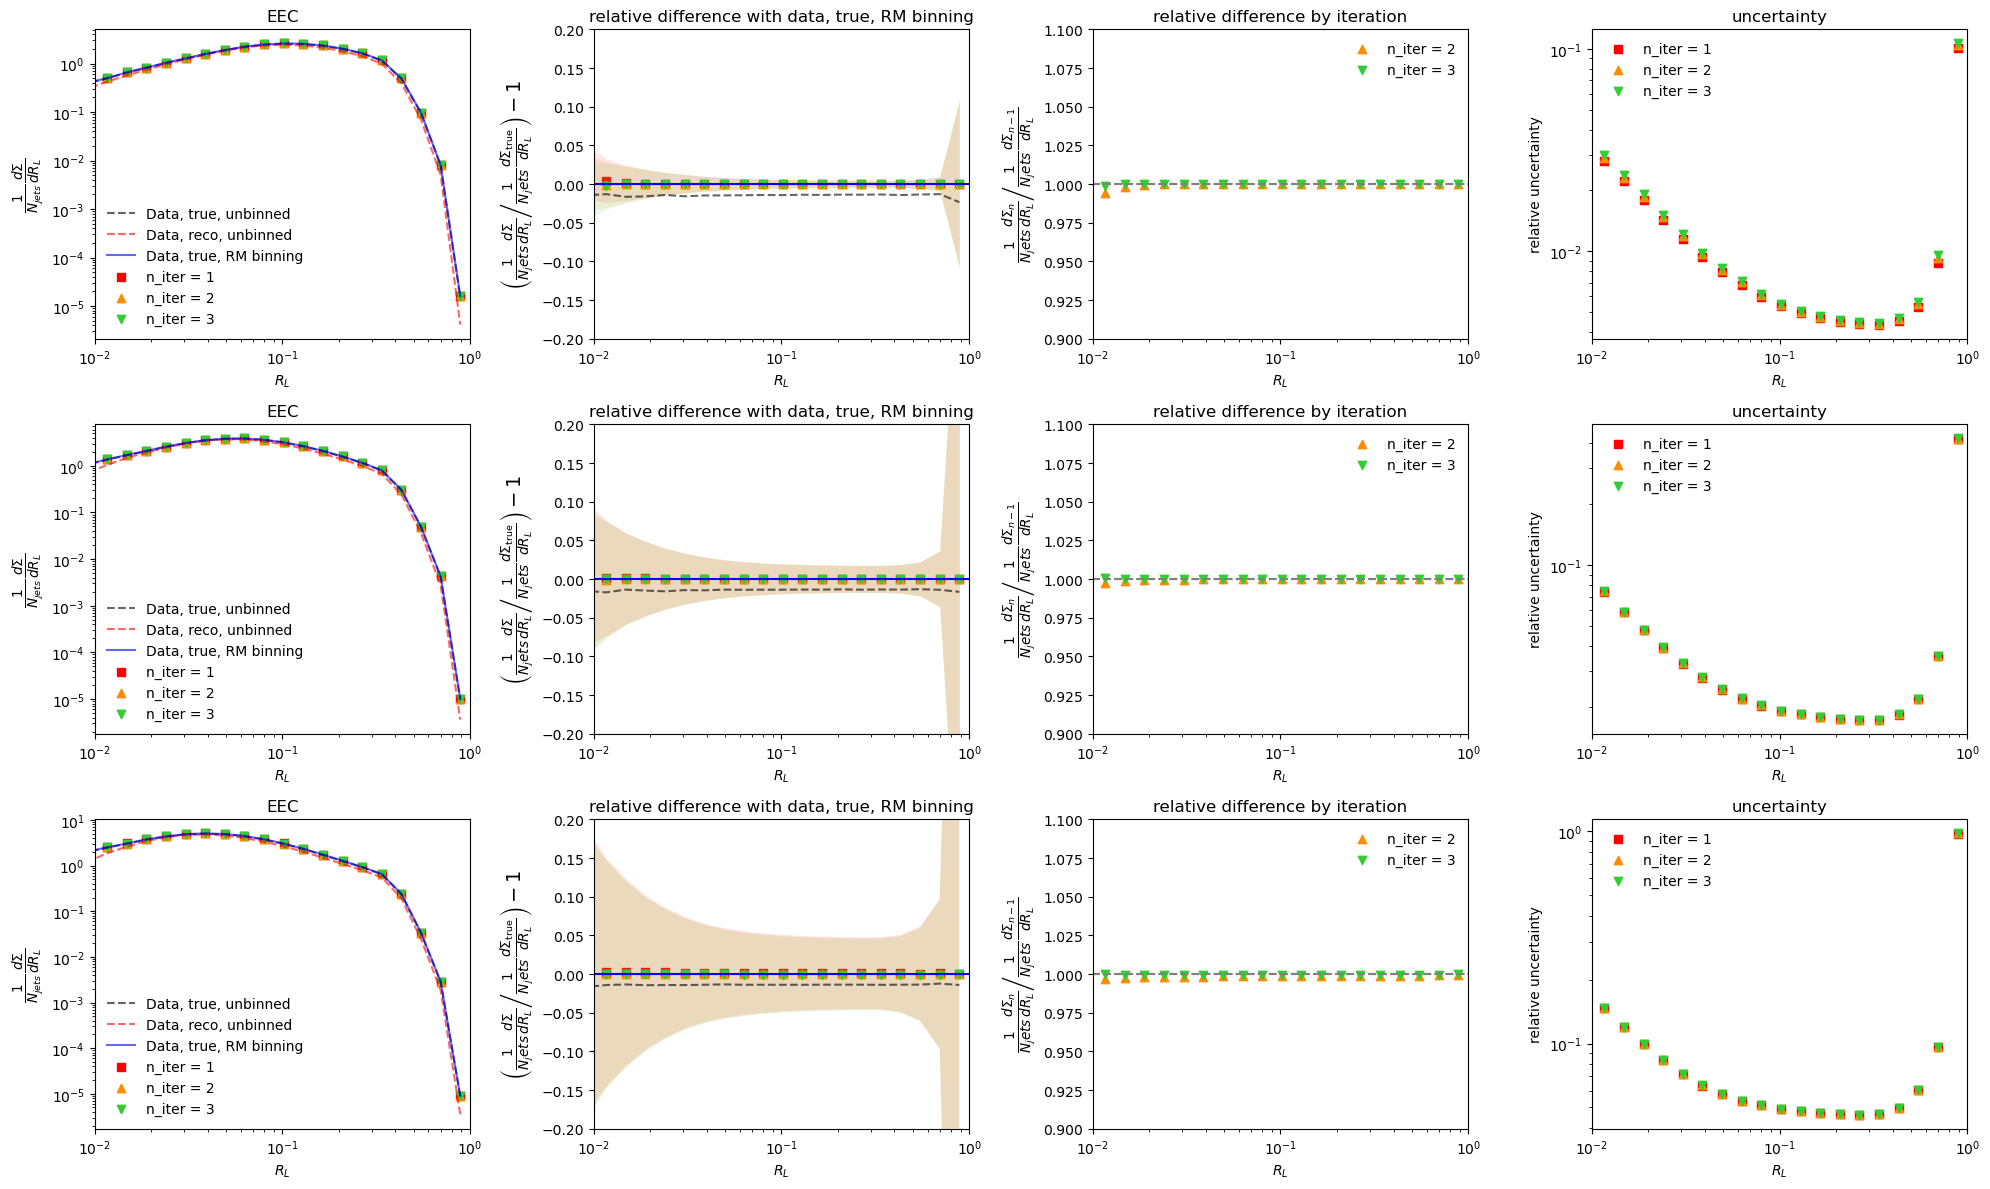

In [17]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################

# EEC distros

it = 3

fig, axes = plt.subplots(3, 4, figsize=(20,12))

j = 0
for i in range(2, 5):    

    ptcut_bins = [i, i+1]
    slice_on_pt = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    ptcut_bins_reco = [i-1, i]
    slice_on_pt_reco = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    U_true_cut = slice_on_pt(h3_true.values()) #  * h3_purity.values())
    U_true_err_cut = slice_on_pt(h3_true.errors())

    U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
    U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

    ###############################  EEC and error CALCULATION  ###############################
    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true_cut]) / (N_jets_true[j] * binwidths[1])
    true_EEC_err = np.array([np.sqrt(np.dot(col, np.array(bincenters[0])**2)) for col in U_true_err_cut]) / (N_jets_true[j] * binwidths[1])

    unfolded_EEC = np.array([ np.array( [np.dot(col, bincenters[0]) for col in U_unfolded_cut[iteration]] ) / binwidths[1] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err_cut[iteration]]) / binwidths[1] for iteration in range(len(theta_unfolded))])

    # add on statistical uncertainty, sum in quadrature
    stat_err = np.array([ np.array( [np.sqrt(np.dot(col, np.array(bincenters[0])**2)) for col in U_unfolded_cut[iteration]] ) / binwidths[1] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.sqrt(unfolded_EEC_err**2 + stat_err**2)

    # divide by number of jets, and propagate error in number of unfolded jets
    unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[j], unfolded_EEC_err[iteration], N_jets_unf_err[j]) for iteration in range(len(theta_unfolded))])
    unfolded_EEC /= N_jets_unf[j]

    ##################################

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[j, 0]

    rl_lims = ax.set_xlim([1E-2, 1])

    # various comparison EEC plots

    # Data, true, unbinned in energy weight (is the actaul truth)
    # should be close to RM binning when energy weight granulatrity is ok, also used to check definition of energy weight log bin center
    # apply purity correction too
    true_eec_unbinned = yslice(h2_true_eec.values(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_true[j] * binwidths[1])
    true_eec_unbinned_err = yslice(h2_true_eec.errors(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_true[j] * binwidths[1])
    ax.plot(bincenters[1], true_eec_unbinned, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    # Data, raw, unbinned in energy weight
    raw_eec_unbinned = yslice(h2_raw_eec.values(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / (N_jets_raw[j] * binwidths[1])
    raw_eec_unbinned_err = yslice(h2_raw_eec.errors(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / (N_jets_raw[j] * binwidths[1])
    ax.plot(bincenters[1], raw_eec_unbinned, color='red', alpha=0.6, linestyle='dashed', label="Data, reco, unbinned")

    # Data, true, RM binning with binnings from the response matrix (i.e. calculated with some binned energy weight)
    ax.plot(bincenters[1], true_EEC, color='blue', alpha=0.6, label="Data, true, RM binning")

    #print(true_eec_unbinned / raw_eec_unbinned)

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("$\\frac{1}{N_{jets}}\\frac{d\Sigma}{dR_L}$", fontsize=14)
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    # row below with the error

    ax = axes[j, 1]

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='blue', linestyle='solid')

    yvals, yerrs = get_ratio_safe(true_eec_unbinned, true_EEC, \
                                        numerr=true_eec_unbinned_err, denomerr=true_EEC_err, filler=1)
    yvals = yvals - 1
    ax.plot(bincenters[1], yvals, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    for iteration in range(it):

        yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                        numerr=unfolded_EEC_err[iteration], denomerr=true_EEC_err, filler=1)
        yvals = yvals - 1

        ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],lw=1, label="n_iter = {}".format(iteration+1))

        ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        
        ax.set_ylabel('$\left(\left.\\frac{1}{N_jets}\\frac{d\Sigma}{dR_L} \middle/ \\frac{1}{N_jets}\\frac{d\Sigma_\\text{true}}{dR_L} \\right.\\right) - 1$', fontsize=14)
        
        ax.set_title("relative difference with data, true, RM binning")
        ax.set_xlabel(labels[1])

        ax.set_xscale('log')
        ax.set_ylim([-0.2, 0.2])
        ax.set_xlim(rl_lims)


    # COL 2: convergence plot (n / n - 1)
    ax = axes[j, 2]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("relative difference by iteration")
        ax.set_xlabel(labels[1])
        ax.set_ylabel('$\left.\\frac{1}{N_jets}\\frac{d\Sigma_n}{dR_L} \middle/ \\frac{1}{N_jets}\\frac{d\Sigma_{n-1}}{dR_L} \\right.$', fontsize=14)
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.9, 1.1])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[j, 3]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("uncertainty")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    j += 1

fig.tight_layout()
plt.show()
